In [1]:
import os
import xarray as xr
import datetime as dt
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import geopandas as gpd
import rasterio
import numpy as np
from shapely.geometry import Point
from rasterio.features import geometry_mask
from rasterio.transform import from_bounds
from matplotlib.colors import LinearSegmentedColormap

(array([ 6712651.,        0.,        0.,        0.,        0.,        0.,
               0.,        0.,        0., 28467121.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <BarContainer object of 10 artists>)

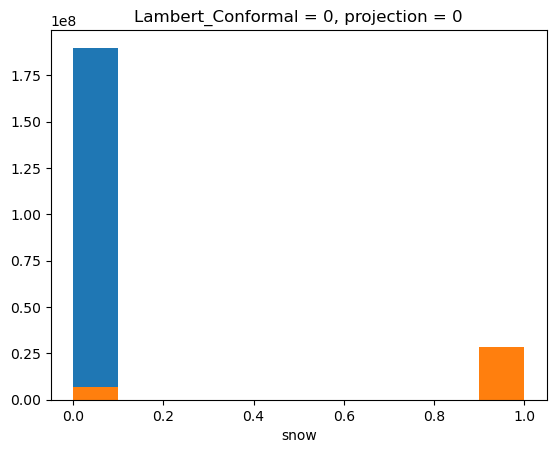

In [10]:
folder_project = 'D:/JALANGLOIS/'
region = 'aac'

years = [2019,2020,2021,2022,2023]

#create a dictionnary to store the dataset with year as key
ros = {}
snow = {}
ice = {}

for year in years:
    file = os.path.join(folder_project, 'ROS_NC', 'ros_%s_%s.nc'%(str(year),  region))
    ds = xr.open_dataset(file)
    ros[year] = ds['ROS']

    #from the IMS_Surface_Values, create a new variable snow with 1 when IMS_Surface_Values = 4,  0 when IMS_Surface_Values = 2 and nan otherwise
    ds['snow'] = xr.where(ds.IMS_Surface_Values == 4, 1, 
                xr.where(ds.IMS_Surface_Values == 2, 0, np.nan))
    
    #from the IMS_Surface_Values, create a new variable ice with 1 when IMS_Surface_Values = 3,  0 when IMS_Surface_Values = 1 and nan otherwise
    ds['ice'] = xr.where(ds.IMS_Surface_Values == 3, 1, 
                xr.where(ds.IMS_Surface_Values == 1, 0, np.nan))


    snow[year] = ds['snow']
    ice[year] = ds['ice']

ros[2023].plot()
snow[2023].plot()


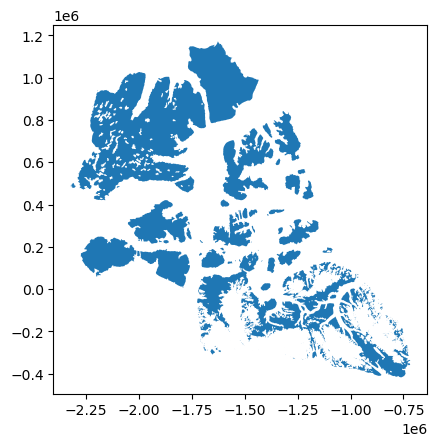

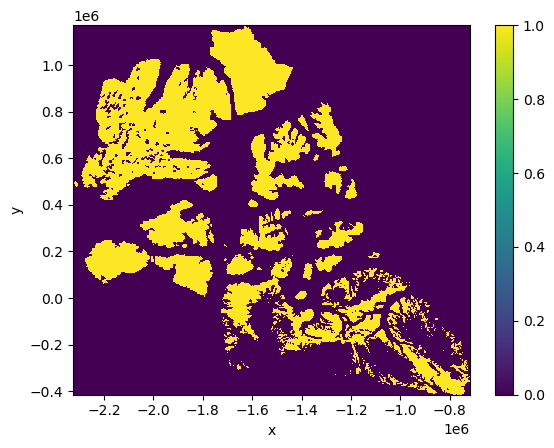

In [3]:
#read region shapefile (negative buffer of 1500 m) and mask the ROS variable
region_path = os.path.join(folder_project,'regions', region, '%s_moins_1500m_without_glaciers.shp'%(region))  
gdf = gpd.read_file(region_path)

gdf = gdf.to_crs(6931)
#print(gdf)

# Get the coordinates of the dataset
x = ds['x'].values
y = ds['y'].values

# Create a 2D array of coordinates (x, y)
x2d, y2d = np.meshgrid(x, y)
coords = np.dstack((x2d, y2d))

# Get the geometries from the shapefile
geometries = gdf.geometry

#plot the geometries
gdf.plot()
plt.show()

# Define the affine transformation using the bounds of the dataset
transform = from_bounds(x.min(), y.min(), x.max(), y.max(), len(x), len(y))


# Use rasterio.features.geometry_mask to create the mask
mask = geometry_mask([geom for geom in geometries],
                     transform=transform,
                     invert=True,
                     out_shape=(len(y), len(x)))

# Create a DataArray for the mask
mask_da = xr.DataArray(mask, coords=[ds['y'], ds['x']], dims=['y', 'x'])

mask_da.plot()
plt.show()


In [11]:
#Calculate the number of ROS per month for both orbit (cumulative)

#iterate over the years to create a new montlhy dictionnary or ros per year
ros_month = {}
for year in years:
    ros_month[year] = ros[year].groupby('time.month').sum(dim='time')
    #mask the data
    ros_month[year] = ros_month[year].where(mask_da, drop=False)




In [12]:
snow_month = {}
ice_month = {}
for year in years:
    snow_month[year] = snow[year].groupby('time.month').sum(dim='time')
    ice_month[year] = ice[year].groupby('time.month').sum(dim='time')


AttributeError: 'DataArray' object has no attribute 'describe'

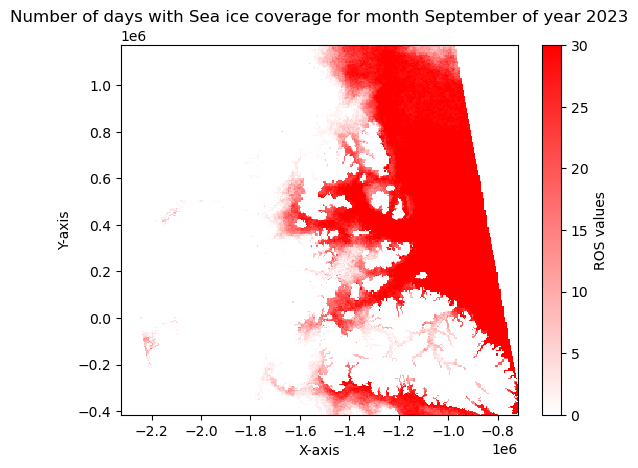

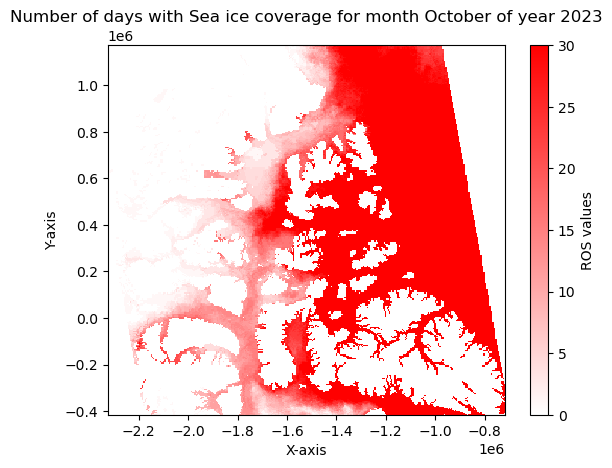

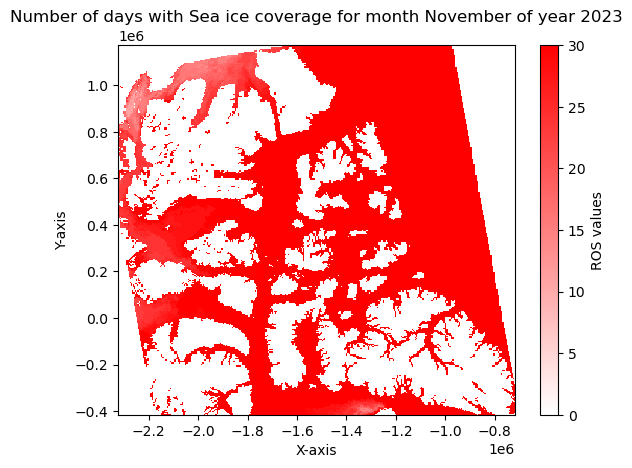

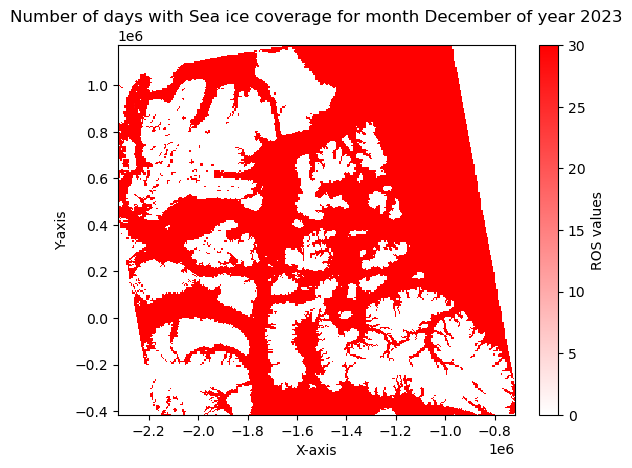

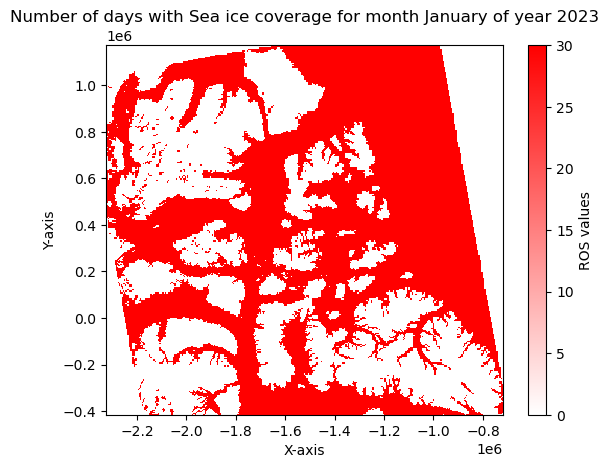

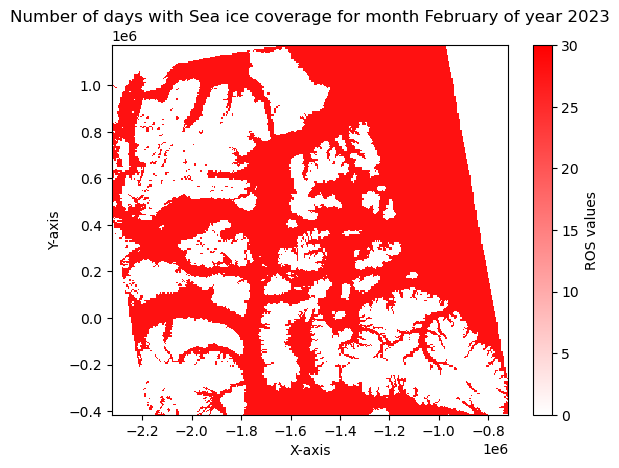

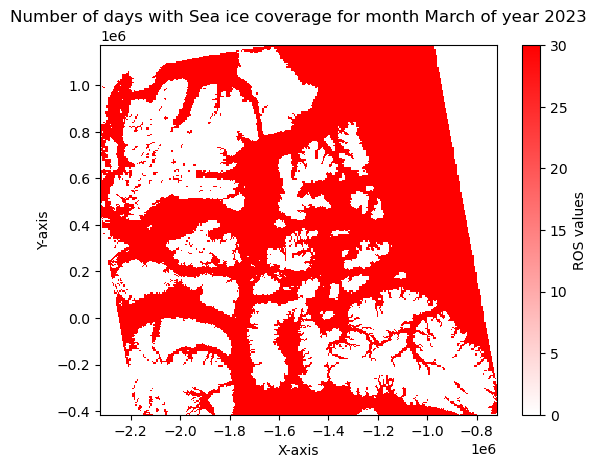

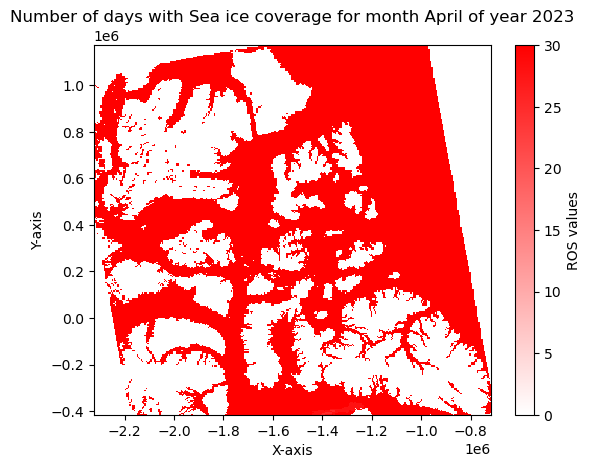

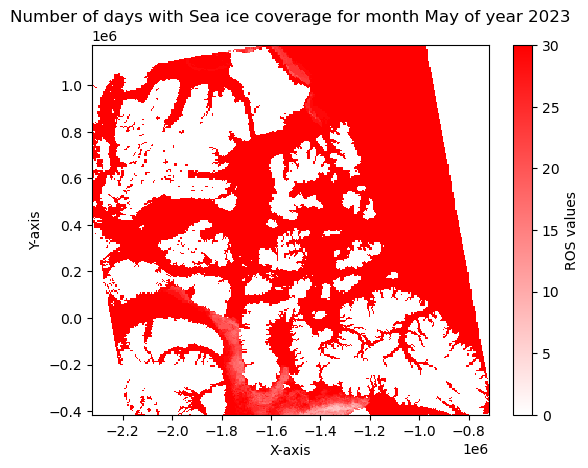

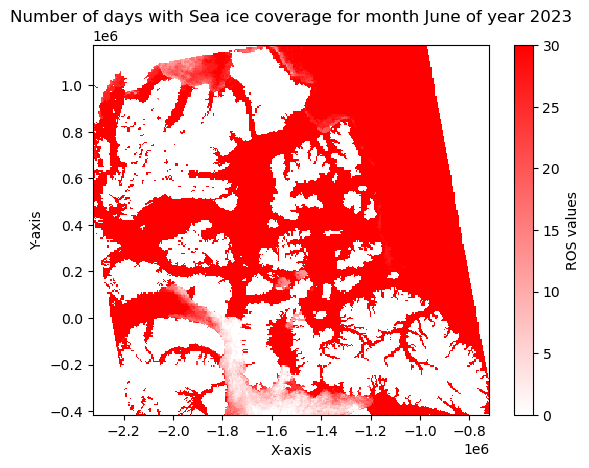

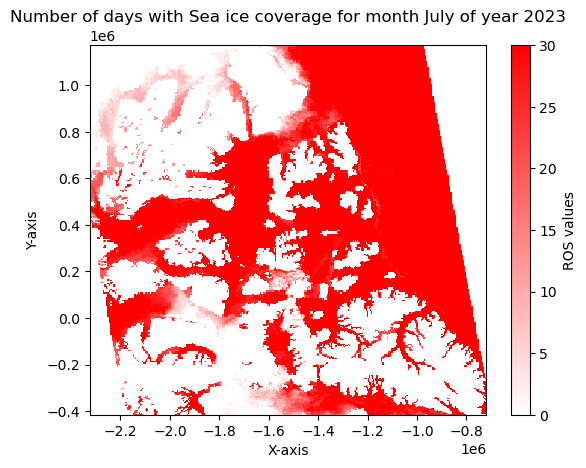

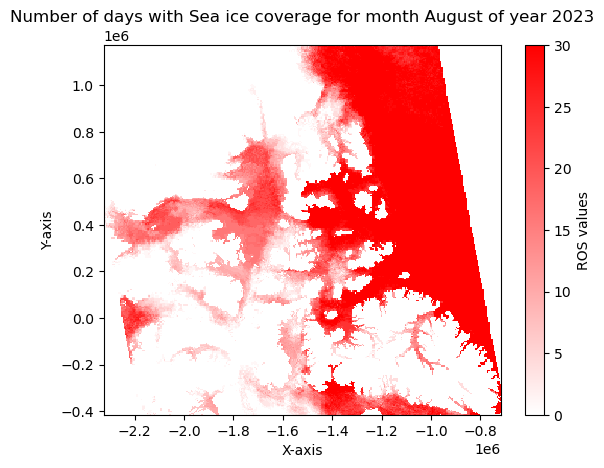

In [7]:

# Define the custom colormap from white to red
colors = [(1, 1, 1), (1, 0, 0)]  # From white to red
n_bins = 256  # Use 256 bins for the colormap
cmap_name = 'white_to_red'
cm = LinearSegmentedColormap.from_list(cmap_name, colors, N=n_bins)


#iterate over the months and plot the ROS
for month in [9,10,11,12,1,2,3,4,5,6,7,8]:
    for year in years:

        subset = ice_month[year].sel(month=month)
        
        # Plot the DataArray using pcolormesh
        fig, ax = plt.subplots()
        c = ax.pcolormesh(subset['x'], subset['y'], subset, cmap=cm, vmin=0, vmax=30)

        # Add a colorbar
        cbar = fig.colorbar(c, ax=ax)
        cbar.set_label('ROS values')
        cbar.set_ticks([0, 5, 10, 15, 20, 25, 30])
        cbar.set_ticklabels(['0', '5', '10', '15', '20', '25', '30'])

        # Set labels and title
        ax.set_xlabel('X-axis')
        ax.set_ylabel('Y-axis')
        ax.set_title('Number of days with Sea ice coverage for month %s of year %s'%(str(dt.date(1900, month, 1).strftime('%B')), str(year)))

        plt.show()
        
        #save the figure
        fig.savefig(os.path.join(folder_project, 'figures', 'sea_ice_days_per_month_%s_%s.png'%(str(year), str(dt.date(1900, month, 1).strftime('%B')))))

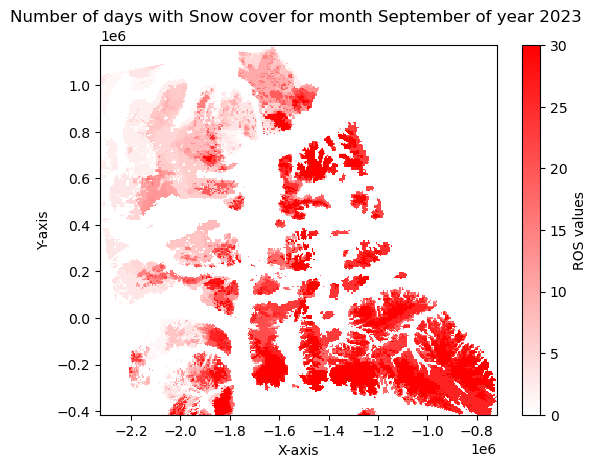

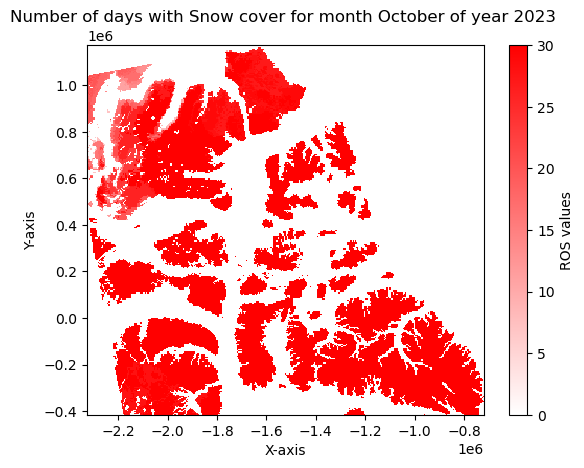

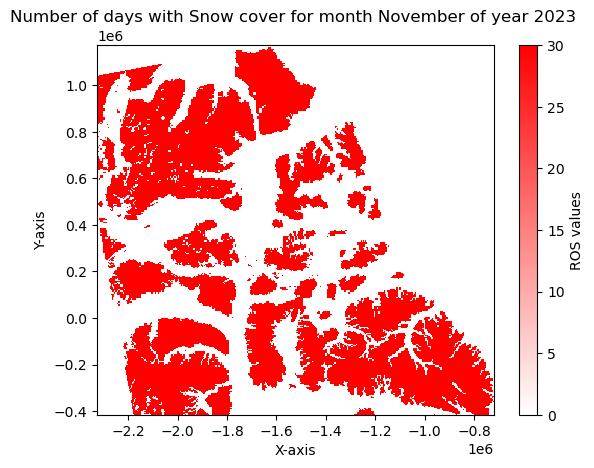

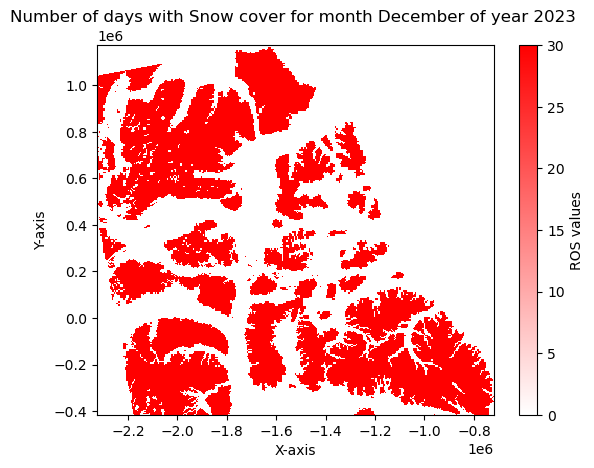

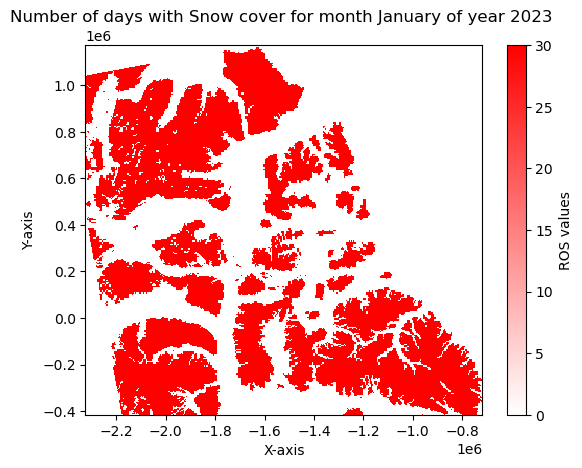

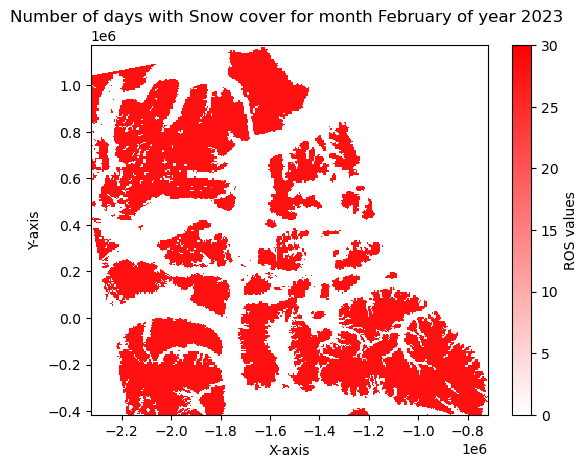

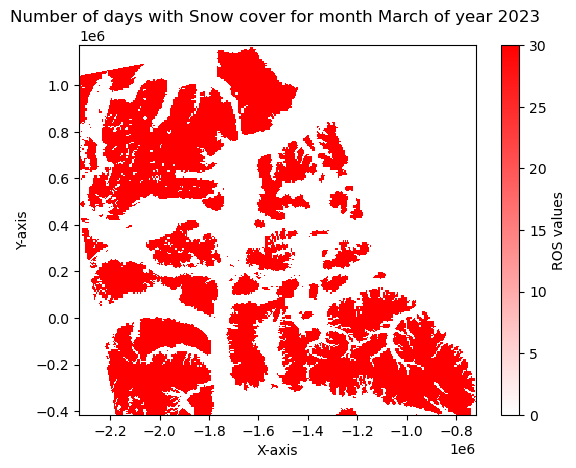

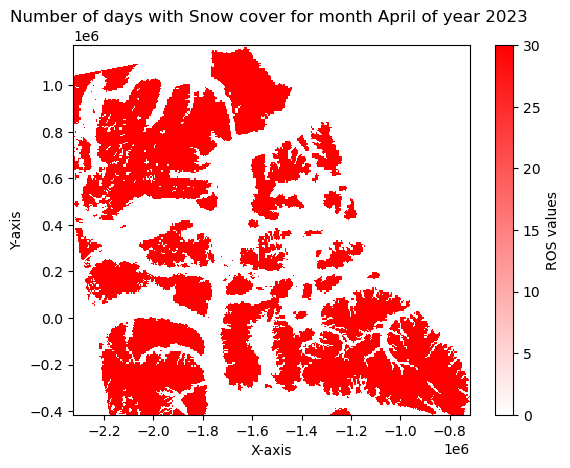

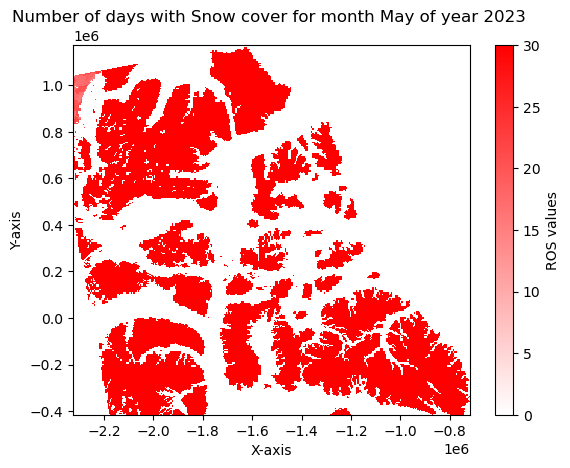

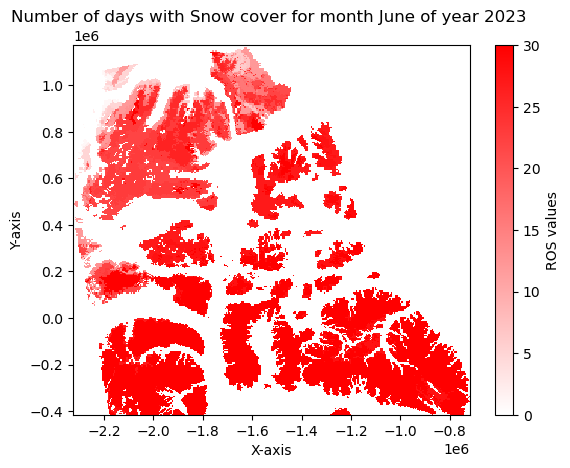

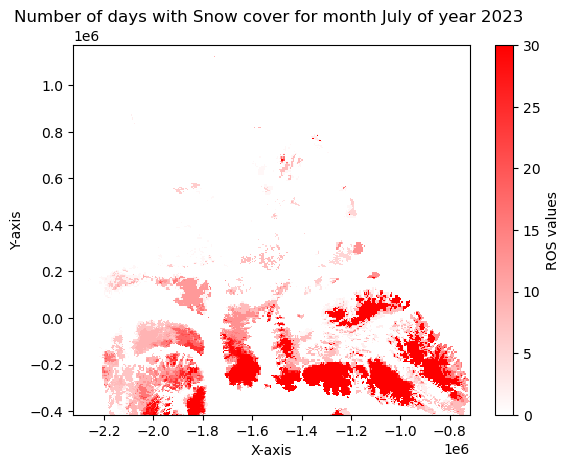

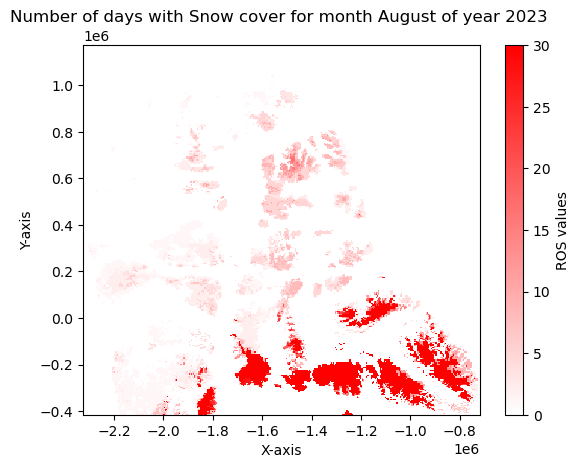

In [8]:

# Define the custom colormap from white to red
colors = [(1, 1, 1), (1, 0, 0)]  # From white to red
n_bins = 256  # Use 256 bins for the colormap
cmap_name = 'white_to_red'
cm = LinearSegmentedColormap.from_list(cmap_name, colors, N=n_bins)


#iterate over the months and plot the ROS
for month in [9,10,11,12,1,2,3,4,5,6,7,8]:
    for year in years:

        subset = snow_month[year].sel(month=month)
        
        # Plot the DataArray using pcolormesh
        fig, ax = plt.subplots()
        c = ax.pcolormesh(subset['x'], subset['y'], subset, cmap=cm, vmin=0, vmax=30)

        # Add a colorbar
        cbar = fig.colorbar(c, ax=ax)
        cbar.set_label('ROS values')
        cbar.set_ticks([0, 5, 10, 15, 20, 25, 30])
        cbar.set_ticklabels(['0', '5', '10', '15', '20', '25', '30'])

        # Set labels and title
        ax.set_xlabel('X-axis')
        ax.set_ylabel('Y-axis')
        ax.set_title('Number of days with Snow cover for %s %s '%(str(dt.date(1900, month, 1).strftime('%B')), str(year)))

        plt.show()

        #save the figure
        fig.savefig(os.path.join(folder_project, 'figures', 'snow_days_per_month_%s_%s.png'%(str(year), str(dt.date(1900, month, 1).strftime('%B')))))

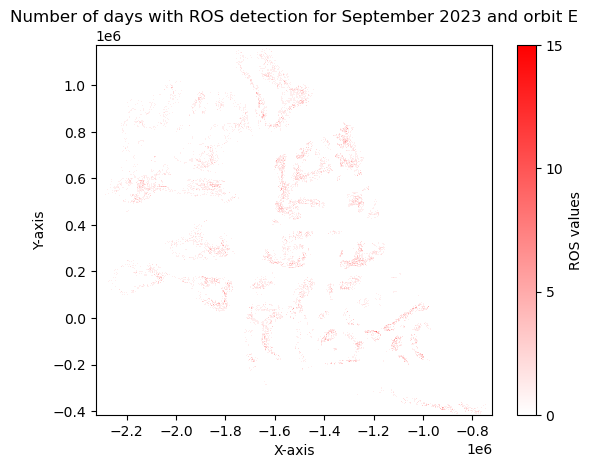

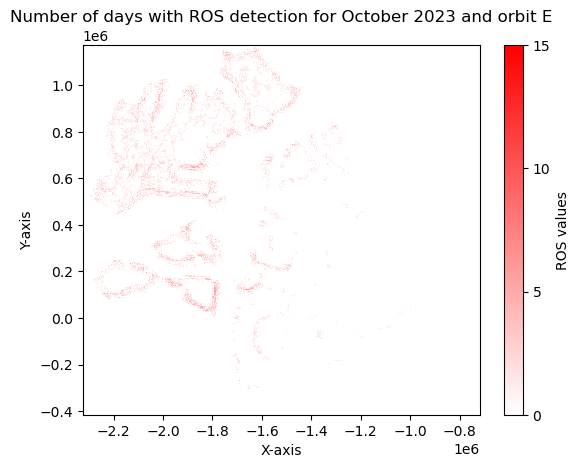

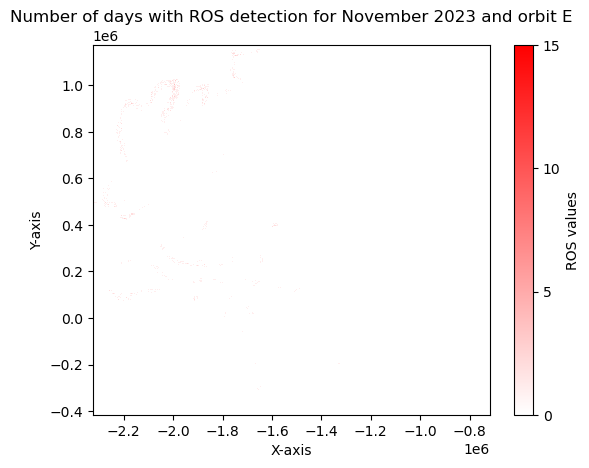

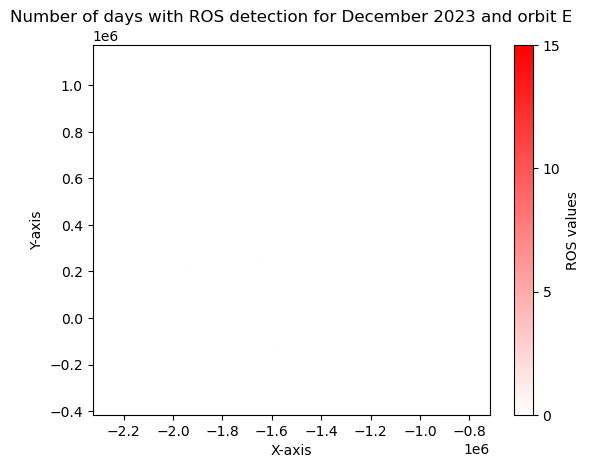

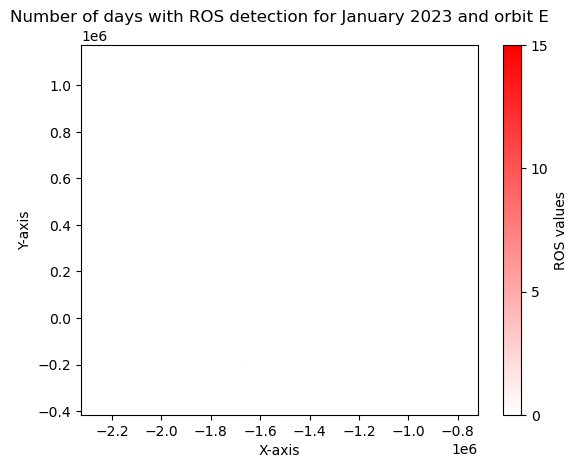

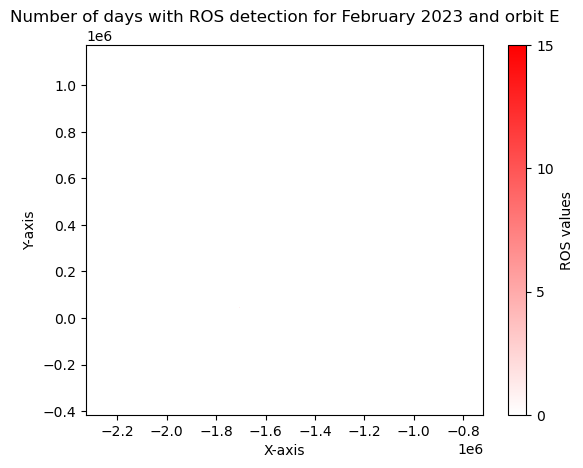

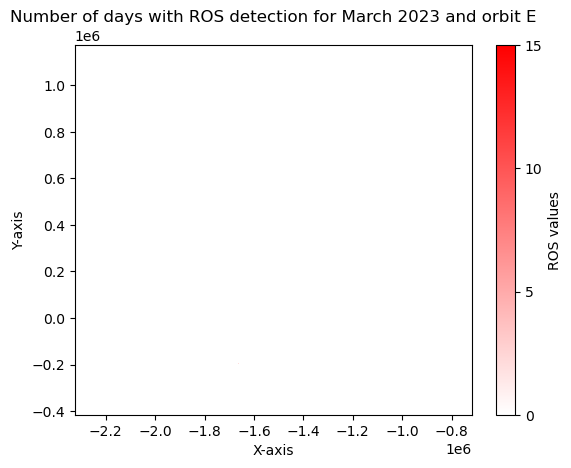

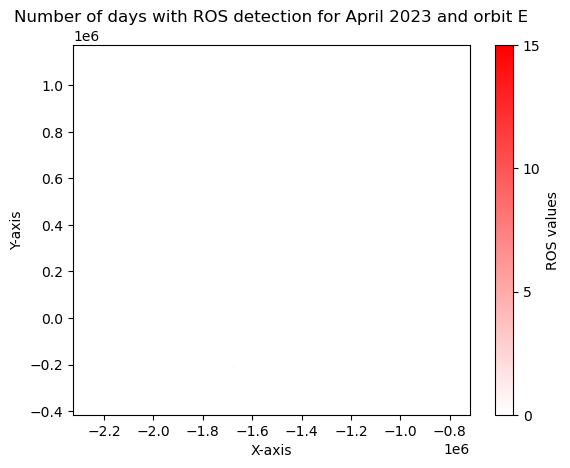

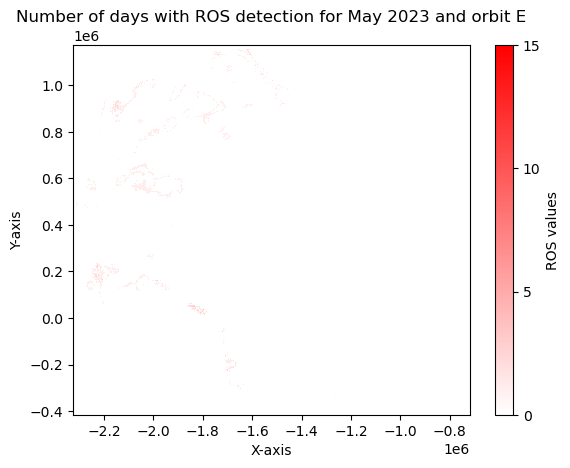

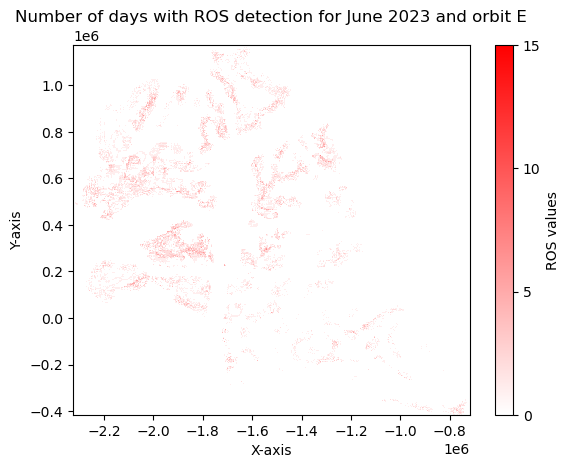

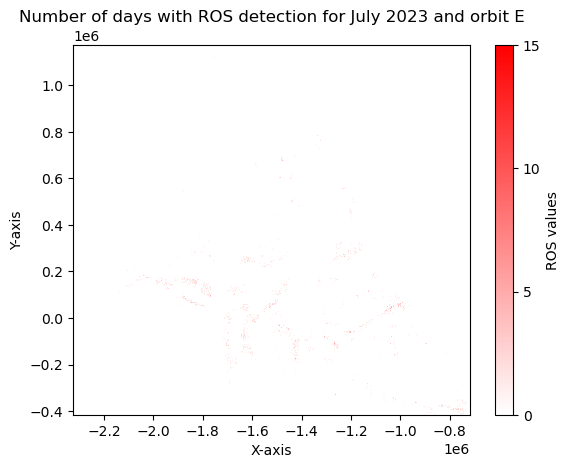

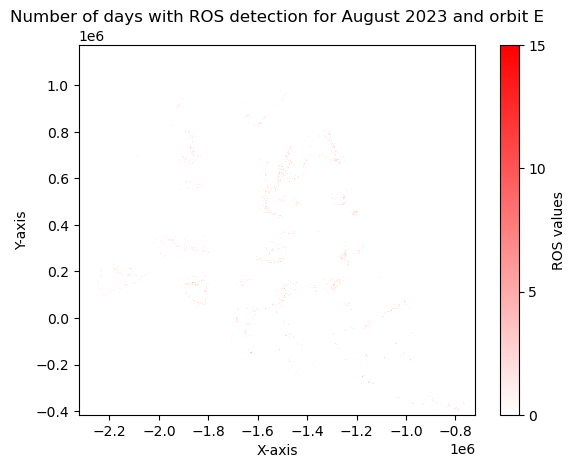

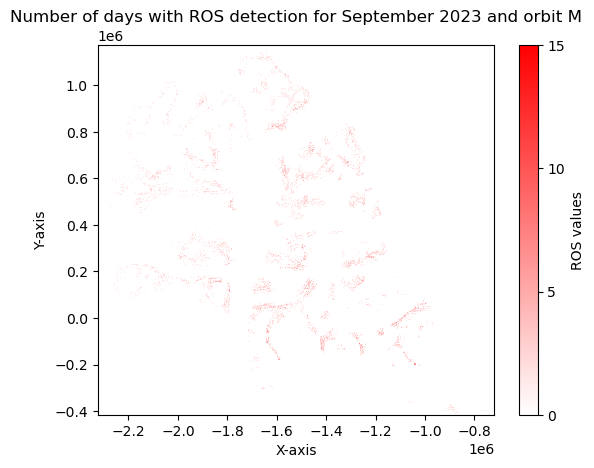

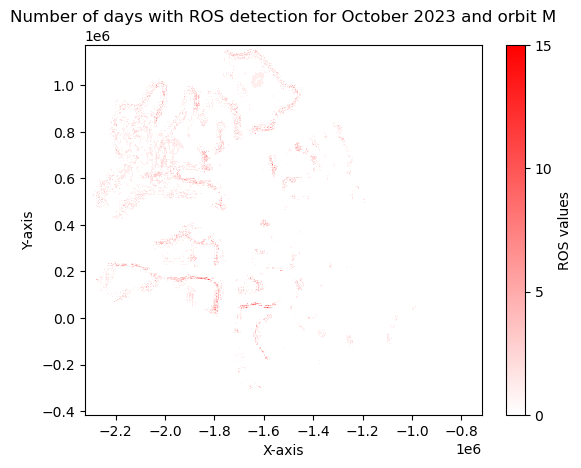

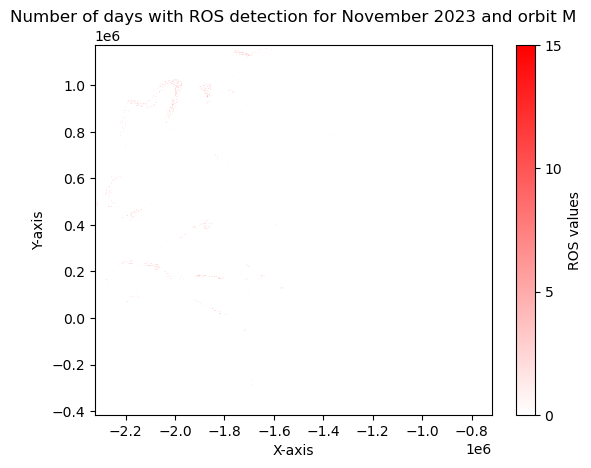

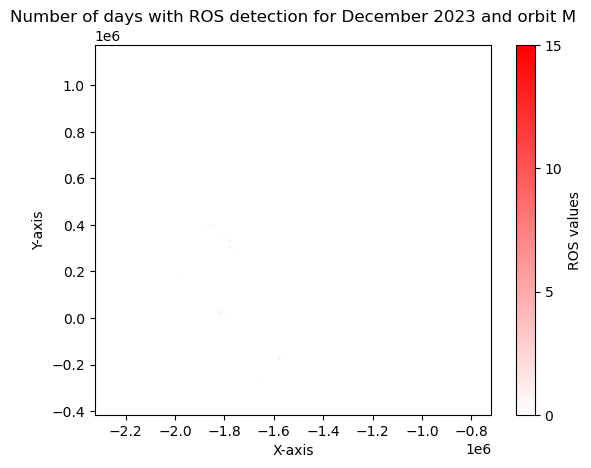

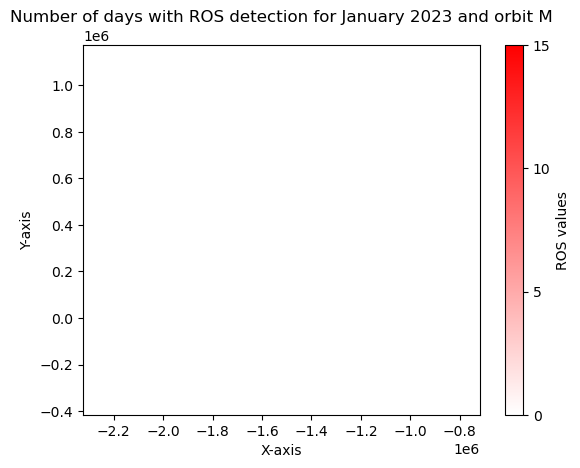

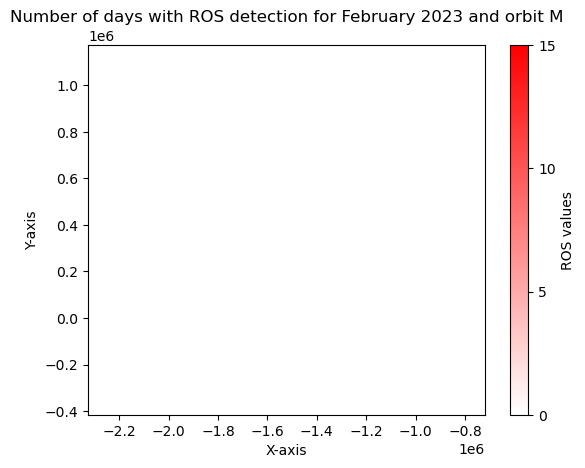

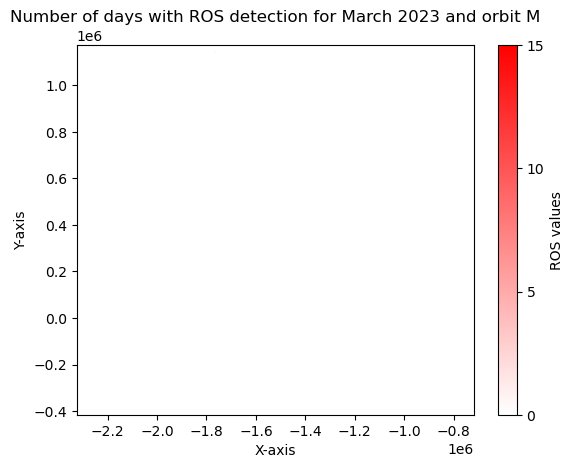

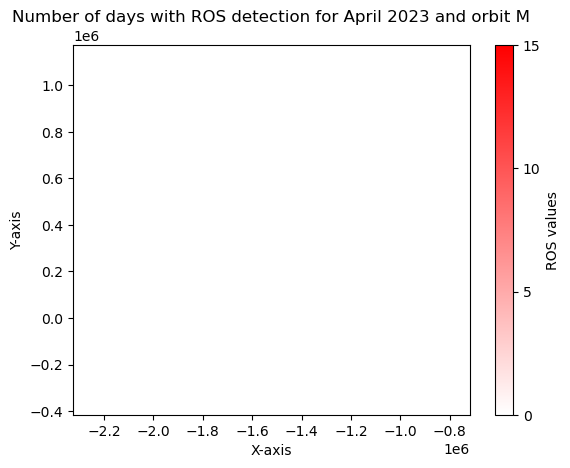

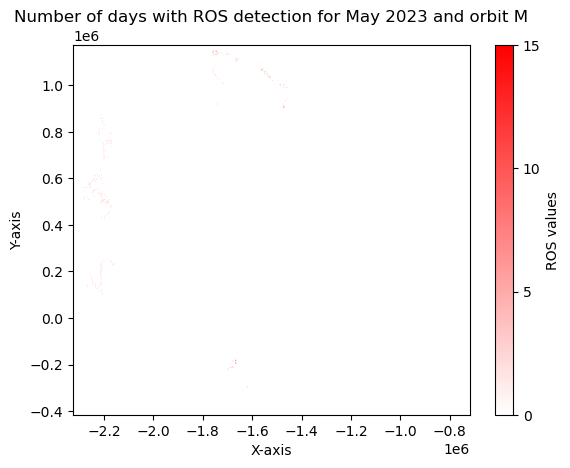

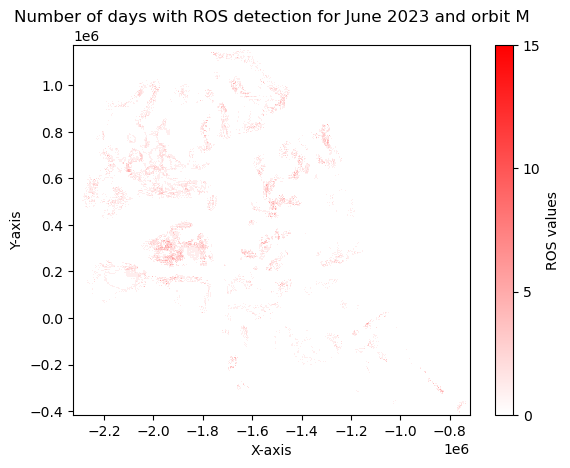

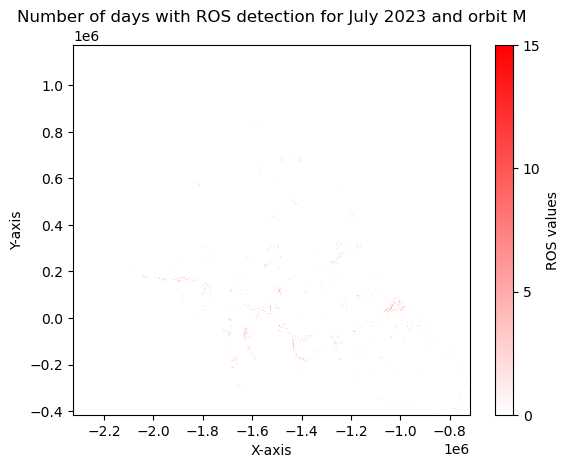

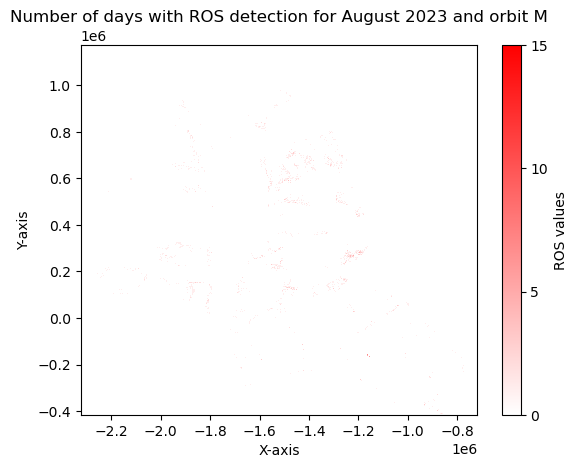

In [9]:
orbits = ['E', 'M']
# Define the custom colormap from white to red
colors = [(1, 1, 1), (1, 0, 0)]  # From white to red
n_bins = 256  # Use 256 bins for the colormap
cmap_name = 'white_to_red'
cm = LinearSegmentedColormap.from_list(cmap_name, colors, N=n_bins)

for orbit in orbits:

    #iterate over the months and plot the ROS
    for month in [9,10,11,12,1,2,3,4,5,6,7,8]:
        for year in years:

            subset = ros_month[year].sel(month=month, orbit=orbit)
            
            # Plot the DataArray using pcolormesh
            fig, ax = plt.subplots()
            c = ax.pcolormesh(subset['x'], subset['y'], subset, cmap=cm, vmin=0, vmax=15)

            # Add a colorbar
            cbar = fig.colorbar(c, ax=ax)
            cbar.set_label('ROS values')
            cbar.set_ticks([0, 5, 10, 15])
            cbar.set_ticklabels(['0', '5', '10', '15'])

            # Set labels and title
            ax.set_xlabel('X-axis')
            ax.set_ylabel('Y-axis')
            ax.set_title('Number of days with ROS detection for %s %s and orbit %s'%(str(dt.date(1900, month, 1).strftime('%B')), str(year), orbit))

            plt.show()
             #save the figure
            fig.savefig(os.path.join(folder_project, 'figures', 'ros_days_per_month_%s_%s_%s.png'%(str(year), str(dt.date(1900, month, 1).strftime('%B')), orbit)))
            

In [4]:
#write to netcdf
file_out = os.path.join(folder_project, 'ROS_NC', 'ros_%s_%s_2.nc'%(str(year), region))
ds.to_netcdf(file_out)

In [ ]:
#iterate from start_date for a number of days
time = datetime(2022,10,1)
nb_days = 30
orbit = 'M'

# Iterate over the range of dates
for i in range(nb_days):
    current_date = time + timedelta(days=i)
    print(current_date.strftime('%Y-%m-%d'))

    ds['ROS'].sel(time=current_date, orbit=orbit).plot(vmin=0,vmax=1)
    plt.show()
#ds['GRP'].sel(time=time, orbit=orbit).plot(vmin=-5,vmax=5)
#plt.show()
